In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
from sklearn.mixture import GaussianMixture
np.random.seed(30)

In [2]:
# UNIMODAL
# -------------------------------------------------------------
# Closed-Form Gaussian CRPS & Objective
# -------------------------------------------------------------
def crps_gaussian(mu, sigma, y):
    z = (y - mu) / sigma
    return sigma * (z * (2.0 * norm.cdf(z) - 1.0) + 2.0 * norm.pdf(z) - 1.0 / np.sqrt(np.pi))

# The objective loss function
def mean_crps(params, y):
    mu, sigma = params[0], np.exp(params[1])
    return np.mean(crps_gaussian(mu, sigma, y))

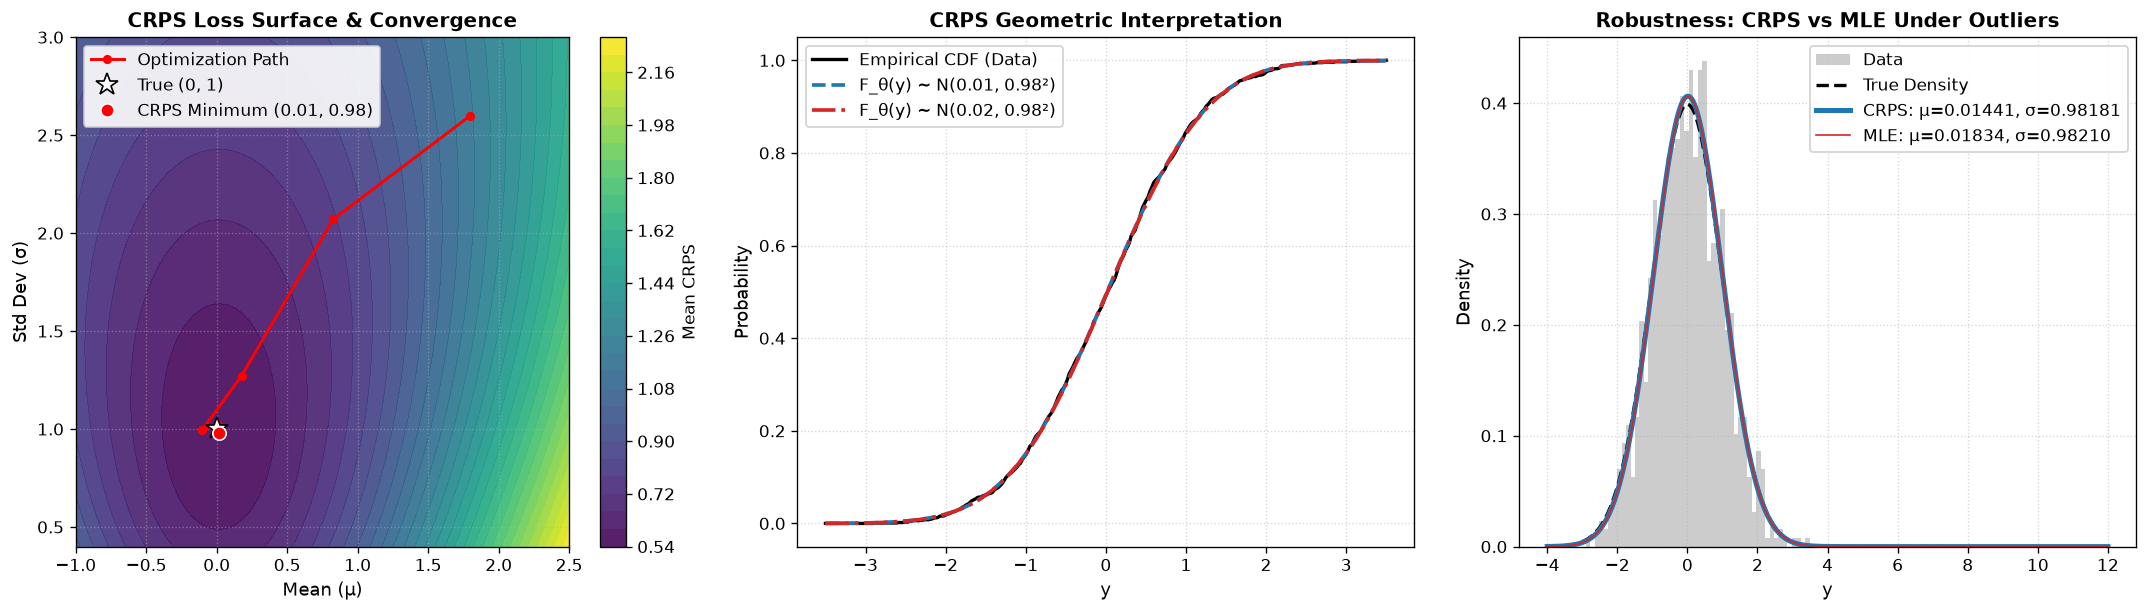

In [3]:
# No outliers
# -------------------------------------------------------------
# Data Generation & Parameter Estimation
# -------------------------------------------------------------
n_samples = 1000
mu_true, sigma_true = 0, 1
clean_data = np.random.normal(mu_true, sigma_true, size=n_samples)
y_clean = clean_data

# Track optimization trajectory
trajectory = []
def callback_fn(xk):
    trajectory.append([xk[0], np.exp(xk[1])])

init_params = [1.8, np.log(2.6)]
trajectory.append([init_params[0], np.exp(init_params[1])])

res = minimize(mean_crps, init_params, args=(y_clean,), method="L-BFGS-B", callback=callback_fn)
mu_hat, sigma_hat = res.x[0], np.exp(res.x[1])
traj = np.array(trajectory)

# -------------------------------------------------------------
# Visualizations
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

# --- Panel 1: Loss Surface and Optimizer Trajectory ---
mu_grid = np.linspace(-1.0, 2.5, 60)
sigma_grid = np.linspace(0.4, 3.0, 60)
M, S = np.meshgrid(mu_grid, sigma_grid)
Z = np.zeros_like(M)

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        Z[i, j] = np.mean(crps_gaussian(M[i, j], S[i, j], y_clean))

cs = axes[0].contourf(M, S, Z, levels=30, cmap="viridis", alpha=0.9)
fig.colorbar(cs, ax=axes[0], label="Mean CRPS")
axes[0].plot(traj[:, 0], traj[:, 1], "r.-", markersize=9, linewidth=1.8, label="Optimization Path")
axes[0].plot(mu_true, sigma_true, "w*", markersize=14, markeredgecolor="black", label=f"True ({mu_true}, {sigma_true})")
axes[0].plot(mu_hat, sigma_hat, "ro", markersize=8, markeredgecolor="white", label=f"CRPS Minimum ({mu_hat:.2f}, {sigma_hat:.2f})")
axes[0].set_title("CRPS Loss Surface & Convergence", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Mean (μ)", fontsize=11)
axes[0].set_ylabel("Std Dev (σ)", fontsize=11)
axes[0].legend(loc="upper left", framealpha=0.9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# MLE parameters for comparison
mu_mle_c = np.mean(y_clean)
sigma_mle_c = np.std(y_clean)

# --- Predictive CDF vs Empirical Step Function ---
x_eval = np.linspace(-3.5, 3.5, 300)
emp_cdf = np.array([np.mean(y_clean <= x) for x in x_eval])
crps_cdf = norm.cdf(x_eval, loc=mu_hat, scale=sigma_hat)
mle_cdf = norm.cdf(x_eval, loc=mu_mle_c, scale=sigma_mle_c)

axes[1].plot(x_eval, emp_cdf, color="black", linewidth=2.0, label="Empirical CDF (Data)")
axes[1].plot(x_eval, crps_cdf, color="tab:blue", linestyle="--", linewidth=2.2, label=f"F_θ(y) ~ N({mu_hat:.2f}, {sigma_hat:.2f}²)")
axes[1].plot(x_eval, mle_cdf, color="tab:red", linestyle="-.", linewidth=2.2, label=f"F_θ(y) ~ N({mu_mle_c:.2f}, {sigma_mle_c:.2f}²)")
axes[1].set_title("CRPS Geometric Interpretation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("y", fontsize=11)
axes[1].set_ylabel("Probability", fontsize=11)
axes[1].legend(loc="upper left", framealpha=0.9)
axes[1].grid(True, linestyle=":", alpha=0.5)

# --- Outlier Robustness: CRPS vs MLE ---
x_plot = np.linspace(-4, 12, 400)
axes[2].hist(y_clean, bins=50, density=True, color="gray", alpha=0.4, label="Data")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_true, sigma_true), "k--", linewidth=2.0, label="True Density")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_hat, sigma_hat), color="tab:blue", linewidth=3, label=f"CRPS: μ={mu_hat:.5f}, σ={sigma_hat:.5f}")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_mle_c, sigma_mle_c), color="tab:red", linewidth=1, label=f"MLE: μ={mu_mle_c:.5f}, σ={sigma_mle_c:.5f}")
axes[2].set_title("Robustness: CRPS vs MLE Under Outliers", fontsize=12, fontweight="bold")
axes[2].set_xlabel("y", fontsize=11)
axes[2].set_ylabel("Density", fontsize=11)
axes[2].legend(loc="upper right", framealpha=0.9)
axes[2].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

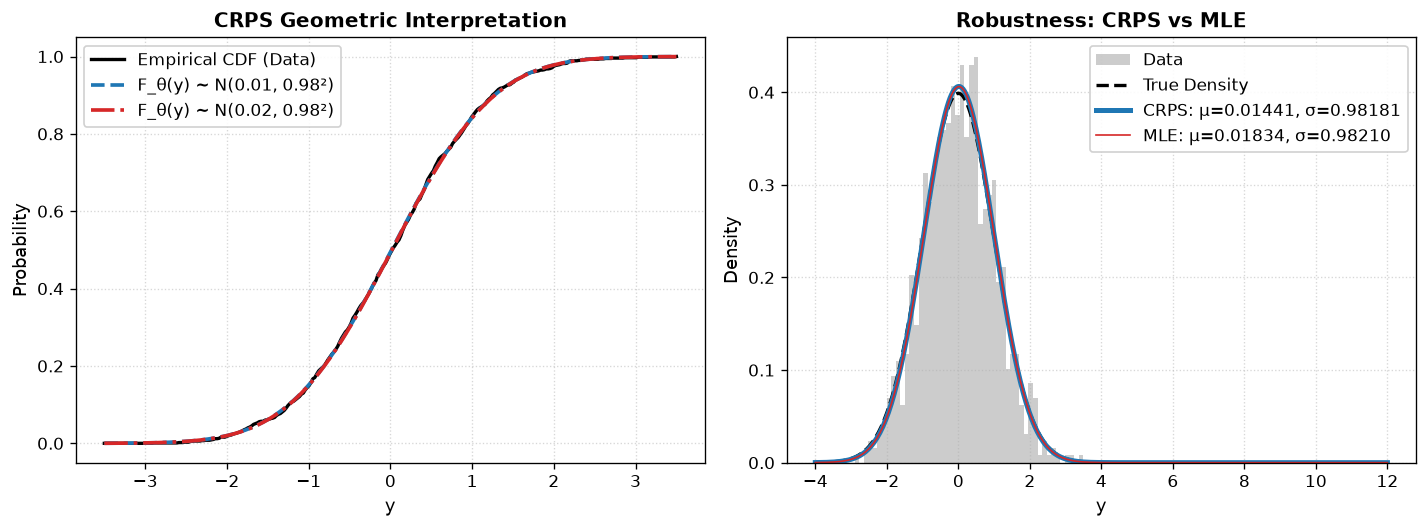

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# MLE parameters for comparison
mu_mle_c = np.mean(y_clean)
sigma_mle_c = np.std(y_clean)

# --- Predictive CDF vs Empirical Step Function ---
x_eval = np.linspace(-3.5, 3.5, 300)
emp_cdf = np.array([np.mean(y_clean <= x) for x in x_eval])
crps_cdf = norm.cdf(x_eval, loc=mu_hat, scale=sigma_hat)
mle_cdf = norm.cdf(x_eval, loc=mu_mle_c, scale=sigma_mle_c)

axes[0].plot(x_eval, emp_cdf, color="black", linewidth=2.0, label="Empirical CDF (Data)")
axes[0].plot(x_eval, crps_cdf, color="tab:blue", linestyle="--", linewidth=2.2, label=f"F_θ(y) ~ N({mu_hat:.2f}, {sigma_hat:.2f}²)")
axes[0].plot(x_eval, mle_cdf, color="tab:red", linestyle="-.", linewidth=2.2, label=f"F_θ(y) ~ N({mu_mle_c:.2f}, {sigma_mle_c:.2f}²)")
axes[0].set_title("CRPS Geometric Interpretation", fontsize=12, fontweight="bold")
axes[0].set_xlabel("y", fontsize=11)
axes[0].set_ylabel("Probability", fontsize=11)
axes[0].legend(loc="upper left", framealpha=0.9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# --- Outlier Robustness: CRPS vs MLE ---
x_plot = np.linspace(-4, 12, 400)
axes[1].hist(y_clean, bins=50, density=True, color="gray", alpha=0.4, label="Data")
axes[1].plot(x_plot, norm.pdf(x_plot, mu_true, sigma_true), "k--", linewidth=2.0, label="True Density")
axes[1].plot(x_plot, norm.pdf(x_plot, mu_hat, sigma_hat), color="tab:blue", linewidth=3, label=f"CRPS: μ={mu_hat:.5f}, σ={sigma_hat:.5f}")
axes[1].plot(x_plot, norm.pdf(x_plot, mu_mle_c, sigma_mle_c), color="tab:red", linewidth=1, label=f"MLE: μ={mu_mle_c:.5f}, σ={sigma_mle_c:.5f}")
axes[1].set_title("Robustness: CRPS vs MLE", fontsize=12, fontweight="bold")
axes[1].set_xlabel("y", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)
axes[1].legend(loc="upper right", framealpha=0.9)
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("iid_no_noise_cdf_pdf.pdf", bbox_inches="tight")
plt.show()

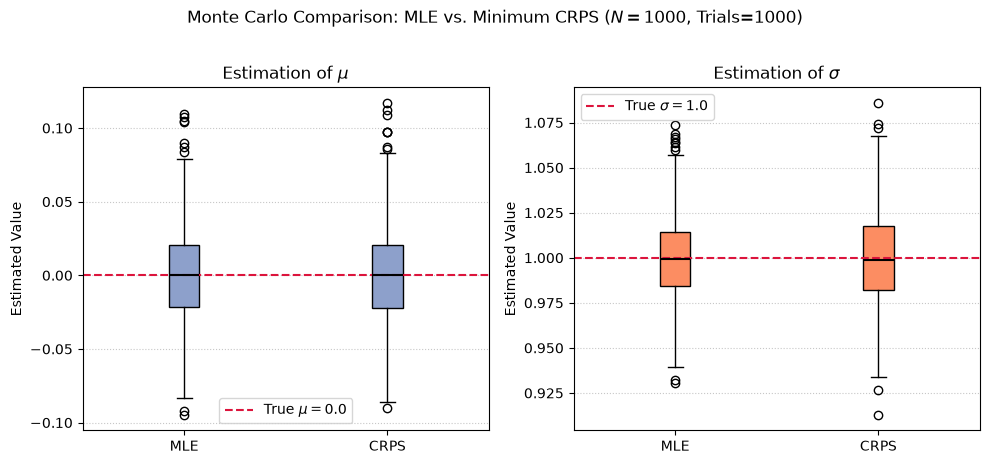

In [9]:
n_trials = 1000              # Number of repetitions
n_samples = 1000             # Sample size per trial
mu_true, sigma_true = 0.0, 1.0

# Storage for results
mu_crps_list = []
sigma_crps_list = []
mu_mle_list = []
sigma_mle_list = []

init_params = [1.8, np.log(2.6)]

for trial in range(n_trials):
    # Generate fresh synthetic data
    y = np.random.normal(mu_true, sigma_true, size=n_samples)

    # Maximum Likelihood Estimation (closed-form)
    mu_mle = np.mean(y)
    sigma_mle = np.std(y, ddof=0)
    mu_mle_list.append(mu_mle)
    sigma_mle_list.append(sigma_mle)
    
    # 3. Minimum CRPS Estimation (numerical optimization)
    res = minimize(
        mean_crps, 
        init_params, 
        args=(y,), 
        method="L-BFGS-B"
    )
    
    mu_crps_list.append(res.x[0])
    sigma_crps_list.append(np.exp(res.x[1]))

# -------------------------------------------------------------
# Visualization: Side-by-Side Box Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Plot for mu estimation
data_mu = [mu_mle_list, mu_crps_list]
axes[0].boxplot(data_mu, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes[0].axhline(mu_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu = {mu_true}$')
axes[0].set_title(r'Estimation of $\mu$')
axes[0].set_ylabel('Estimated Value')
axes[0].grid(axis='y', linestyle=':', alpha=0.7)
axes[0].legend()

# Plot for sigma estimation
data_sigma = [sigma_mle_list, sigma_crps_list]
axes[1].boxplot(data_sigma, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[1].axhline(sigma_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma = {sigma_true}$')
axes[1].set_title(r'Estimation of $\sigma$')
axes[1].set_ylabel('Estimated Value')
axes[1].grid(axis='y', linestyle=':', alpha=0.7)
axes[1].legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.savefig("iid_no_noise_est.pdf", bbox_inches="tight")
plt.show()

In [166]:
mu_mle_arr = np.array(mu_mle_list)
sigma_mle_arr = np.array(sigma_mle_list)
mu_crps_arr = np.array(mu_crps_list)
sigma_crps_arr = np.array(sigma_crps_list)
print(r"Mean MLE: ", np.mean(mu_mle_arr), "Mean Sigma MLE: ", np.mean(sigma_mle_arr))
print(r"Mean CRPS: ", np.mean(mu_crps_arr), "Mean Sigma CRPS: ", np.mean(sigma_crps_arr))

Mean MLE:  -0.0005256530124540626 Mean Sigma MLE:  0.9997235197160126
Mean CRPS:  -0.0006619107269991003 Mean Sigma CRPS:  0.999718051934494


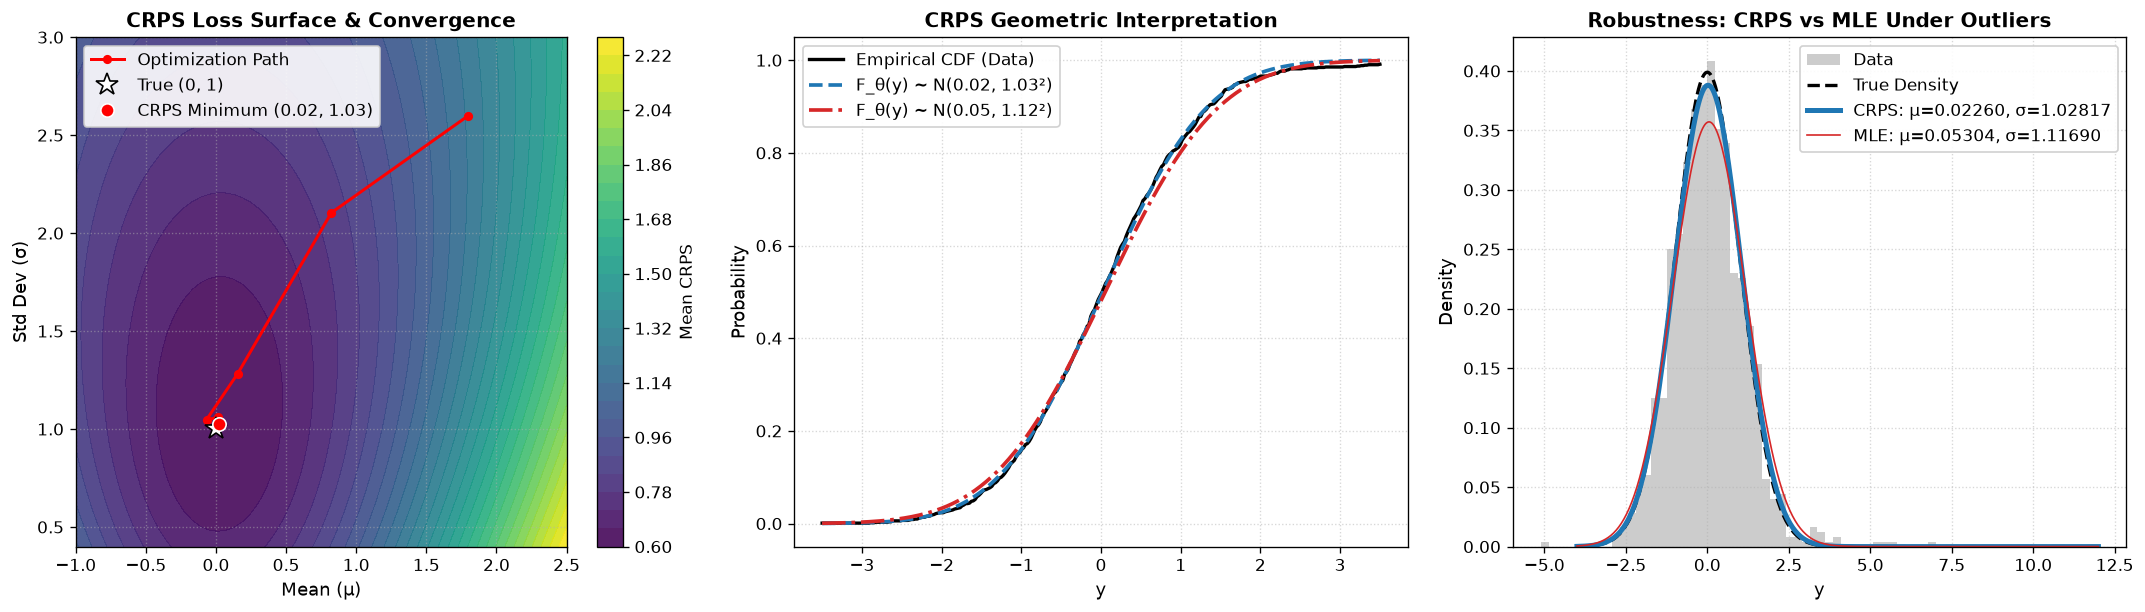

In [167]:
# 2% outliers
# -------------------------------------------------------------
# Data Generation & Parameter Estimation
# -------------------------------------------------------------
n_samples = 1000
n_outliers = 0.02*n_samples
mu_true, sigma_true = 0, 1
clean_data = np.random.normal(mu_true, sigma_true, size=n_samples)
outlier_data = np.random.normal(3, 2, size=int(n_outliers))
y_clean = np.concatenate([clean_data, outlier_data])

# Track optimization trajectory
trajectory = []
def callback_fn(xk):
    trajectory.append([xk[0], np.exp(xk[1])])

init_params = [1.8, np.log(2.6)]
trajectory.append([init_params[0], np.exp(init_params[1])])

res = minimize(mean_crps, init_params, args=(y_clean,), method="L-BFGS-B", callback=callback_fn)
mu_hat, sigma_hat = res.x[0], np.exp(res.x[1])
traj = np.array(trajectory)

# -------------------------------------------------------------
# Visualizations
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

# --- Panel 1: Loss Surface and Optimizer Trajectory ---
mu_grid = np.linspace(-1.0, 2.5, 60)
sigma_grid = np.linspace(0.4, 3.0, 60)
M, S = np.meshgrid(mu_grid, sigma_grid)
Z = np.zeros_like(M)

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        Z[i, j] = np.mean(crps_gaussian(M[i, j], S[i, j], y_clean))

cs = axes[0].contourf(M, S, Z, levels=30, cmap="viridis", alpha=0.9)
fig.colorbar(cs, ax=axes[0], label="Mean CRPS")
axes[0].plot(traj[:, 0], traj[:, 1], "r.-", markersize=9, linewidth=1.8, label="Optimization Path")
axes[0].plot(mu_true, sigma_true, "w*", markersize=14, markeredgecolor="black", label=f"True ({mu_true}, {sigma_true})")
axes[0].plot(mu_hat, sigma_hat, "ro", markersize=8, markeredgecolor="white", label=f"CRPS Minimum ({mu_hat:.2f}, {sigma_hat:.2f})")
axes[0].set_title("CRPS Loss Surface & Convergence", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Mean (μ)", fontsize=11)
axes[0].set_ylabel("Std Dev (σ)", fontsize=11)
axes[0].legend(loc="upper left", framealpha=0.9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# MLE parameters for comparison
mu_mle_c = np.mean(y_clean)
sigma_mle_c = np.std(y_clean)

# --- Predictive CDF vs Empirical Step Function ---
x_eval = np.linspace(-3.5, 3.5, 300)
emp_cdf = np.array([np.mean(y_clean <= x) for x in x_eval])
crps_cdf = norm.cdf(x_eval, loc=mu_hat, scale=sigma_hat)
mle_cdf = norm.cdf(x_eval, loc=mu_mle_c, scale=sigma_mle_c)

axes[1].plot(x_eval, emp_cdf, color="black", linewidth=2.0, label="Empirical CDF (Data)")
axes[1].plot(x_eval, crps_cdf, color="tab:blue", linestyle="--", linewidth=2.2, label=f"F_θ(y) ~ N({mu_hat:.2f}, {sigma_hat:.2f}²)")
axes[1].plot(x_eval, mle_cdf, color="tab:red", linestyle="-.", linewidth=2.2, label=f"F_θ(y) ~ N({mu_mle_c:.2f}, {sigma_mle_c:.2f}²)")
axes[1].set_title("CRPS Geometric Interpretation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("y", fontsize=11)
axes[1].set_ylabel("Probability", fontsize=11)
axes[1].legend(loc="upper left", framealpha=0.9)
axes[1].grid(True, linestyle=":", alpha=0.5)

# --- Outlier Robustness: CRPS vs MLE ---
x_plot = np.linspace(-4, 12, 400)
axes[2].hist(y_clean, bins=50, density=True, color="gray", alpha=0.4, label="Data")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_true, sigma_true), "k--", linewidth=2.0, label="True Density")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_hat, sigma_hat), color="tab:blue", linewidth=3, label=f"CRPS: μ={mu_hat:.5f}, σ={sigma_hat:.5f}")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_mle_c, sigma_mle_c), color="tab:red", linewidth=1, label=f"MLE: μ={mu_mle_c:.5f}, σ={sigma_mle_c:.5f}")
axes[2].set_title("Robustness: CRPS vs MLE Under Outliers", fontsize=12, fontweight="bold")
axes[2].set_xlabel("y", fontsize=11)
axes[2].set_ylabel("Density", fontsize=11)
axes[2].legend(loc="upper right", framealpha=0.9)
axes[2].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

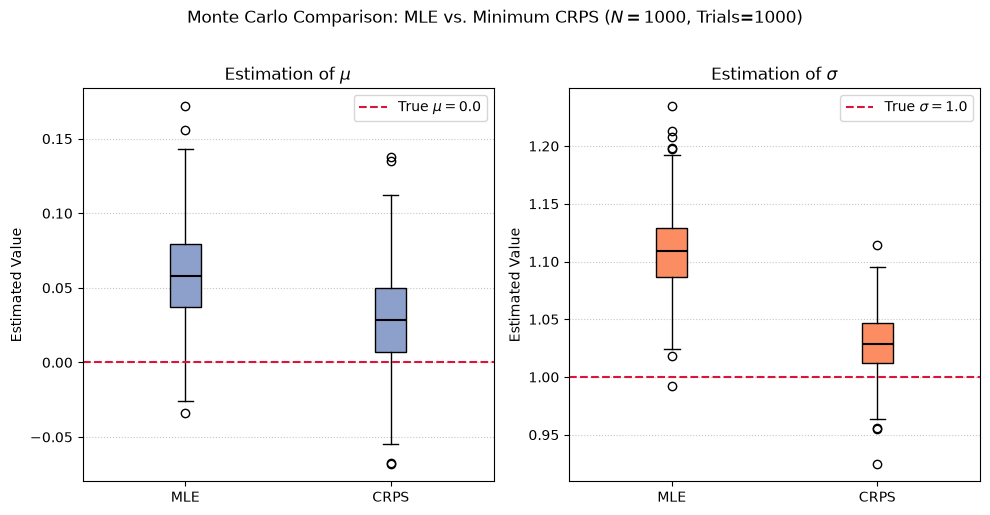

In [168]:
n_trials = 1000              # Number of repetitions
n_samples = 1000             # Sample size per trial
mu_true, sigma_true = 0.0, 1.0

# Storage for results
mu_crps_list = []
sigma_crps_list = []
mu_mle_list = []
sigma_mle_list = []

init_params = [1.8, np.log(2.6)]

for trial in range(n_trials):
    # Generate fresh synthetic data
    clean_data = np.random.normal(mu_true, sigma_true, size=n_samples)
    outlier_data = np.random.normal(3, 2, size=int(n_outliers))
    y = np.concatenate([clean_data, outlier_data])

    # Maximum Likelihood Estimation (closed-form)
    mu_mle = np.mean(y)
    sigma_mle = np.std(y, ddof=0)
    mu_mle_list.append(mu_mle)
    sigma_mle_list.append(sigma_mle)
    
    # 3. Minimum CRPS Estimation (numerical optimization)
    res = minimize(
        mean_crps, 
        init_params, 
        args=(y,), 
        method="L-BFGS-B"
    )
    
    mu_crps_list.append(res.x[0])
    sigma_crps_list.append(np.exp(res.x[1]))

# -------------------------------------------------------------
# Visualization: Side-by-Side Box Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot for mu estimation
data_mu = [mu_mle_list, mu_crps_list]
axes[0].boxplot(data_mu, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes[0].axhline(mu_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu = {mu_true}$')
axes[0].set_title(r'Estimation of $\mu$')
axes[0].set_ylabel('Estimated Value')
axes[0].grid(axis='y', linestyle=':', alpha=0.7)
axes[0].legend()

# Plot for sigma estimation
data_sigma = [sigma_mle_list, sigma_crps_list]
axes[1].boxplot(data_sigma, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[1].axhline(sigma_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma = {sigma_true}$')
axes[1].set_title(r'Estimation of $\sigma$')
axes[1].set_ylabel('Estimated Value')
axes[1].grid(axis='y', linestyle=':', alpha=0.7)
axes[1].legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.show()

In [169]:
mu_mle_arr = np.array(mu_mle_list)
sigma_mle_arr = np.array(sigma_mle_list)
mu_crps_arr = np.array(mu_crps_list)
sigma_crps_arr = np.array(sigma_crps_list)
print(r"Mean MLE: ", np.mean(mu_mle_arr), "Mean Sigma MLE: ", np.mean(sigma_mle_arr))
print(r"Mean CRPS: ", np.mean(mu_crps_arr), "Mean Sigma CRPS: ", np.mean(sigma_crps_arr))

Mean MLE:  0.058296932919602695 Mean Sigma MLE:  1.1092548244760032
Mean CRPS:  0.028757618582216225 Mean Sigma CRPS:  1.0295571241019554


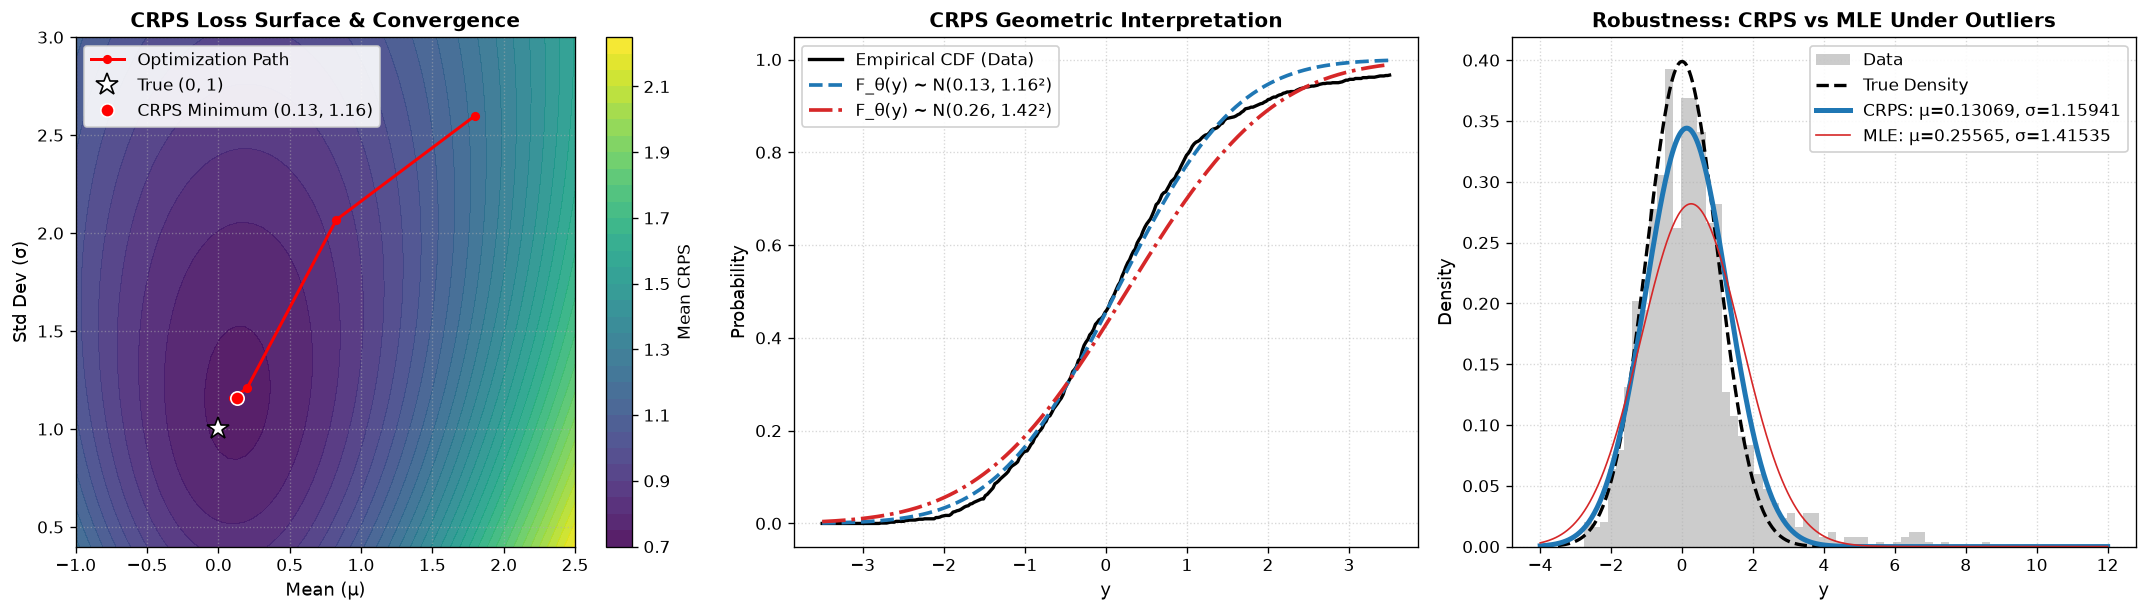

In [10]:
# 10% outliers
# -------------------------------------------------------------
# Data Generation & Parameter Estimation
# -------------------------------------------------------------
n_samples = 1000
n_outliers = 0.1*n_samples
mu_true, sigma_true = 0, 1
clean_data = np.random.normal(mu_true, sigma_true, size=n_samples)
outlier_data = np.random.normal(3, 2, size=int(n_outliers))
y_clean = np.concatenate([clean_data, outlier_data])

# Track optimization trajectory
trajectory = []
def callback_fn(xk):
    trajectory.append([xk[0], np.exp(xk[1])])

init_params = [1.8, np.log(2.6)]
trajectory.append([init_params[0], np.exp(init_params[1])])

res = minimize(mean_crps, init_params, args=(y_clean,), method="L-BFGS-B", callback=callback_fn)
mu_hat, sigma_hat = res.x[0], np.exp(res.x[1])
traj = np.array(trajectory)

# -------------------------------------------------------------
# Visualizations
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

# --- Panel 1: Loss Surface and Optimizer Trajectory ---
mu_grid = np.linspace(-1.0, 2.5, 60)
sigma_grid = np.linspace(0.4, 3.0, 60)
M, S = np.meshgrid(mu_grid, sigma_grid)
Z = np.zeros_like(M)

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        Z[i, j] = np.mean(crps_gaussian(M[i, j], S[i, j], y_clean))

cs = axes[0].contourf(M, S, Z, levels=30, cmap="viridis", alpha=0.9)
fig.colorbar(cs, ax=axes[0], label="Mean CRPS")
axes[0].plot(traj[:, 0], traj[:, 1], "r.-", markersize=9, linewidth=1.8, label="Optimization Path")
axes[0].plot(mu_true, sigma_true, "w*", markersize=14, markeredgecolor="black", label=f"True ({mu_true}, {sigma_true})")
axes[0].plot(mu_hat, sigma_hat, "ro", markersize=8, markeredgecolor="white", label=f"CRPS Minimum ({mu_hat:.2f}, {sigma_hat:.2f})")
axes[0].set_title("CRPS Loss Surface & Convergence", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Mean (μ)", fontsize=11)
axes[0].set_ylabel("Std Dev (σ)", fontsize=11)
axes[0].legend(loc="upper left", framealpha=0.9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# MLE parameters for comparison
mu_mle_c = np.mean(y_clean)
sigma_mle_c = np.std(y_clean)

# --- Predictive CDF vs Empirical Step Function ---
x_eval = np.linspace(-3.5, 3.5, 300)
emp_cdf = np.array([np.mean(y_clean <= x) for x in x_eval])
crps_cdf = norm.cdf(x_eval, loc=mu_hat, scale=sigma_hat)
mle_cdf = norm.cdf(x_eval, loc=mu_mle_c, scale=sigma_mle_c)

axes[1].plot(x_eval, emp_cdf, color="black", linewidth=2.0, label="Empirical CDF (Data)")
axes[1].plot(x_eval, crps_cdf, color="tab:blue", linestyle="--", linewidth=2.2, label=f"F_θ(y) ~ N({mu_hat:.2f}, {sigma_hat:.2f}²)")
axes[1].plot(x_eval, mle_cdf, color="tab:red", linestyle="-.", linewidth=2.2, label=f"F_θ(y) ~ N({mu_mle_c:.2f}, {sigma_mle_c:.2f}²)")
axes[1].set_title("CRPS Geometric Interpretation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("y", fontsize=11)
axes[1].set_ylabel("Probability", fontsize=11)
axes[1].legend(loc="upper left", framealpha=0.9)
axes[1].grid(True, linestyle=":", alpha=0.5)

# --- Outlier Robustness: CRPS vs MLE ---
x_plot = np.linspace(-4, 12, 400)
axes[2].hist(y_clean, bins=50, density=True, color="gray", alpha=0.4, label="Data")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_true, sigma_true), "k--", linewidth=2.0, label="True Density")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_hat, sigma_hat), color="tab:blue", linewidth=3, label=f"CRPS: μ={mu_hat:.5f}, σ={sigma_hat:.5f}")
axes[2].plot(x_plot, norm.pdf(x_plot, mu_mle_c, sigma_mle_c), color="tab:red", linewidth=1, label=f"MLE: μ={mu_mle_c:.5f}, σ={sigma_mle_c:.5f}")
axes[2].set_title("Robustness: CRPS vs MLE Under Outliers", fontsize=12, fontweight="bold")
axes[2].set_xlabel("y", fontsize=11)
axes[2].set_ylabel("Density", fontsize=11)
axes[2].legend(loc="upper right", framealpha=0.9)
axes[2].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

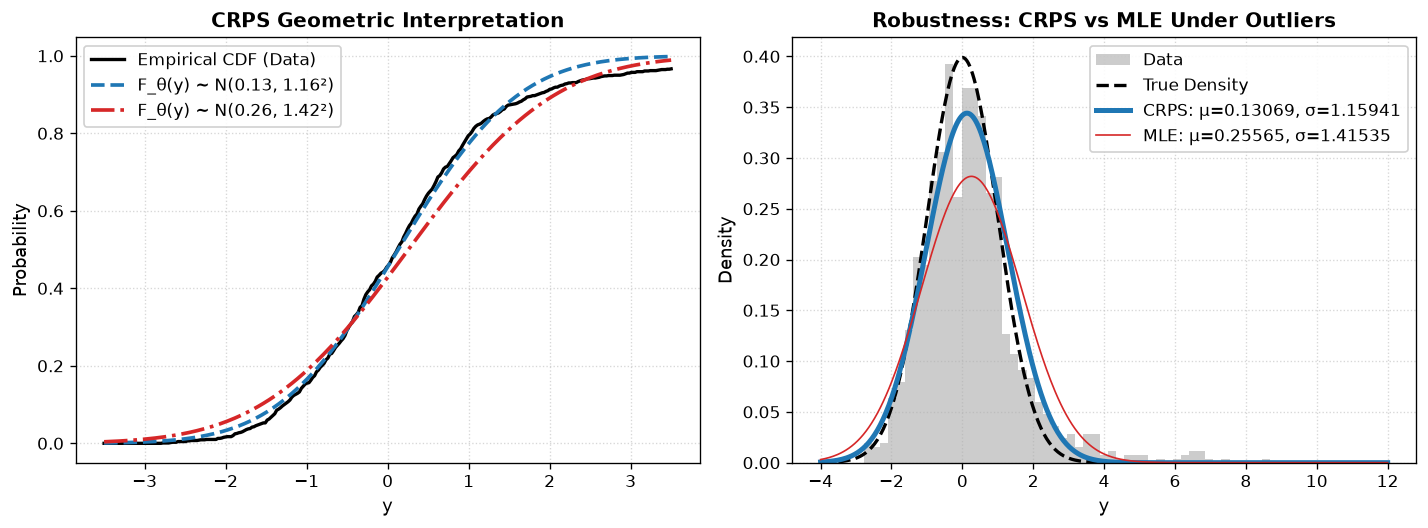

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# MLE parameters for comparison
mu_mle_c = np.mean(y_clean)
sigma_mle_c = np.std(y_clean)

# --- Predictive CDF vs Empirical Step Function ---
x_eval = np.linspace(-3.5, 3.5, 300)
emp_cdf = np.array([np.mean(y_clean <= x) for x in x_eval])
crps_cdf = norm.cdf(x_eval, loc=mu_hat, scale=sigma_hat)
mle_cdf = norm.cdf(x_eval, loc=mu_mle_c, scale=sigma_mle_c)

axes[0].plot(x_eval, emp_cdf, color="black", linewidth=2.0, label="Empirical CDF (Data)")
axes[0].plot(x_eval, crps_cdf, color="tab:blue", linestyle="--", linewidth=2.2, label=f"F_θ(y) ~ N({mu_hat:.2f}, {sigma_hat:.2f}²)")
axes[0].plot(x_eval, mle_cdf, color="tab:red", linestyle="-.", linewidth=2.2, label=f"F_θ(y) ~ N({mu_mle_c:.2f}, {sigma_mle_c:.2f}²)")
axes[0].set_title("CRPS Geometric Interpretation", fontsize=12, fontweight="bold")
axes[0].set_xlabel("y", fontsize=11)
axes[0].set_ylabel("Probability", fontsize=11)
axes[0].legend(loc="upper left", framealpha=0.9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# --- Outlier Robustness: CRPS vs MLE ---
x_plot = np.linspace(-4, 12, 400)
axes[1].hist(y_clean, bins=50, density=True, color="gray", alpha=0.4, label="Data")
axes[1].plot(x_plot, norm.pdf(x_plot, mu_true, sigma_true), "k--", linewidth=2.0, label="True Density")
axes[1].plot(x_plot, norm.pdf(x_plot, mu_hat, sigma_hat), color="tab:blue", linewidth=3, label=f"CRPS: μ={mu_hat:.5f}, σ={sigma_hat:.5f}")
axes[1].plot(x_plot, norm.pdf(x_plot, mu_mle_c, sigma_mle_c), color="tab:red", linewidth=1, label=f"MLE: μ={mu_mle_c:.5f}, σ={sigma_mle_c:.5f}")
axes[1].set_title("Robustness: CRPS vs MLE Under Outliers", fontsize=12, fontweight="bold")
axes[1].set_xlabel("y", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)
axes[1].legend(loc="upper right", framealpha=0.9)
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("iid_0.1_outliers_cdf_pdf.pdf", bbox_inches="tight")
plt.show()

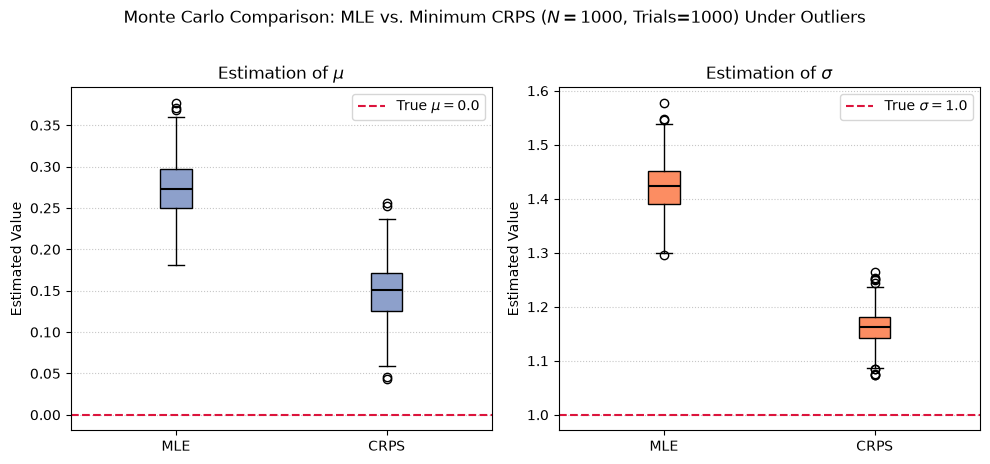

In [15]:
n_trials = 1000              # Number of repetitions
n_samples = 1000             # Sample size per trial
mu_true, sigma_true = 0.0, 1.0

# Storage for results
mu_crps_list = []
sigma_crps_list = []
mu_mle_list = []
sigma_mle_list = []

init_params = [1.8, np.log(2.6)]

for trial in range(n_trials):
    # Generate fresh synthetic data
    clean_data = np.random.normal(mu_true, sigma_true, size=n_samples)
    outlier_data = np.random.normal(3, 2, size=int(n_outliers))
    y = np.concatenate([clean_data, outlier_data])

    # Maximum Likelihood Estimation (closed-form)
    mu_mle = np.mean(y)
    sigma_mle = np.std(y, ddof=0)
    mu_mle_list.append(mu_mle)
    sigma_mle_list.append(sigma_mle)
    
    # 3. Minimum CRPS Estimation (numerical optimization)
    res = minimize(
        mean_crps, 
        init_params, 
        args=(y,), 
        method="L-BFGS-B"
    )
    
    mu_crps_list.append(res.x[0])
    sigma_crps_list.append(np.exp(res.x[1]))

# -------------------------------------------------------------
# Visualization: Side-by-Side Box Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Plot for mu estimation
data_mu = [mu_mle_list, mu_crps_list]
axes[0].boxplot(data_mu, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes[0].axhline(mu_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu = {mu_true}$')
axes[0].set_title(r'Estimation of $\mu$')
axes[0].set_ylabel('Estimated Value')
axes[0].grid(axis='y', linestyle=':', alpha=0.7)
axes[0].legend()

# Plot for sigma estimation
data_sigma = [sigma_mle_list, sigma_crps_list]
axes[1].boxplot(data_sigma, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[1].axhline(sigma_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma = {sigma_true}$')
axes[1].set_title(r'Estimation of $\sigma$')
axes[1].set_ylabel('Estimated Value')
axes[1].grid(axis='y', linestyle=':', alpha=0.7)
axes[1].legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials}) Under Outliers', y=1.02)
plt.tight_layout()
plt.savefig("iid_noise_est.pdf", bbox_inches="tight")
plt.show()

In [172]:
mu_mle_arr = np.array(mu_mle_list)
sigma_mle_arr = np.array(sigma_mle_list)
mu_crps_arr = np.array(mu_crps_list)
sigma_crps_arr = np.array(sigma_crps_list)
print(r"Mean MLE: ", np.mean(mu_mle_arr), "Mean Sigma MLE: ", np.mean(sigma_mle_arr))
print(r"Mean CRPS: ", np.mean(mu_crps_arr), "Mean Sigma CRPS: ", np.mean(sigma_crps_arr))

Mean MLE:  0.2730087602597785 Mean Sigma MLE:  1.42185301904817
Mean CRPS:  0.14984650503342783 Mean Sigma CRPS:  1.162442885185538


In [173]:
# BIMODAL
# -------------------------------------------------------------
# Generate Ground-Truth Bimodal Data
# -------------------------------------------------------------
# Clean data
n_samples = 1000
w_true = 0.4
mu1_true, sigma1_true = -2.5, 0.8
mu2_true, sigma2_true = 2.5, 1.0

# Sample from mixture: 0.4 * N(-2.5, 0.8^2) + 0.6 * N(2.5, 1.0^2)
# Clean data
comp = np.random.binomial(1, 1 - w_true, size=n_samples)
y_obs = np.where(
    comp == 0,
    np.random.normal(mu1_true, sigma1_true, size=n_samples),
    np.random.normal(mu2_true, sigma2_true, size=n_samples)
)

In [174]:
# Closed-Form CRPS for a 2-Component Gaussian Mixture
def _expected_abs_diff(mu_diff, total_var):
    """E|X1 - X2| for independent Gaussians X1 ~ N(mu1, s1^2), X2 ~ N(mu2, s2^2)."""
    s = np.sqrt(total_var)
    z = mu_diff / s
    return s * (2.0 * norm.pdf(z) + z * (2.0 * norm.cdf(z) - 1.0))

def crps_mixture2(w, mu1, sigma1, mu2, sigma2, y):
    """Vectorized CRPS for w*N(mu1, s1^2) + (1-w)*N(mu2, s2^2)."""
    # Term 1: E|X - y|
    z1 = (y - mu1) / sigma1
    ey1 = (y - mu1) * (2.0 * norm.cdf(z1) - 1.0) + 2.0 * sigma1 * norm.pdf(z1)
    
    z2 = (y - mu2) / sigma2
    ey2 = (y - mu2) * (2.0 * norm.cdf(z2) - 1.0) + 2.0 * sigma2 * norm.pdf(z2)
    
    term1 = w * ey1 + (1.0 - w) * ey2
    
    # Term 2: (1/2) E|X - X'|
    exx = (
        (w ** 2) * (2.0 * sigma1 / np.sqrt(np.pi))
        + ((1.0 - w) ** 2) * (2.0 * sigma2 / np.sqrt(np.pi))
        + 2.0 * w * (1.0 - w) * _expected_abs_diff(mu1 - mu2, sigma1**2 + sigma2**2)
    )
    return term1 - 0.5 * exx

# Objective function over unconstrained parameters
def objective_crps_gmm(params, y):
    # Parameter transformations:
    # logit_w -> w in (0, 1), log_sigma -> sigma > 0
    w = 1.0 / (1.0 + np.exp(-params[0]))
    mu1 = params[1]
    sigma1 = np.exp(params[2])
    mu2 = params[3]
    sigma2 = np.exp(params[4])
    return np.mean(crps_mixture2(w, mu1, sigma1, mu2, sigma2, y))


Parameter  | True     | CRPS       | EM (MLE)  
----------------------------------------------
w          | 0.400    | 0.406      | 0.409     
mu_1       | -2.500   | -2.555     | -2.548    
sigma_1    | 0.800    | 0.833      | 0.838     
mu_2       | 2.500    | 2.463      | 2.479     
sigma_2    | 1.000    | 1.054      | 1.009     


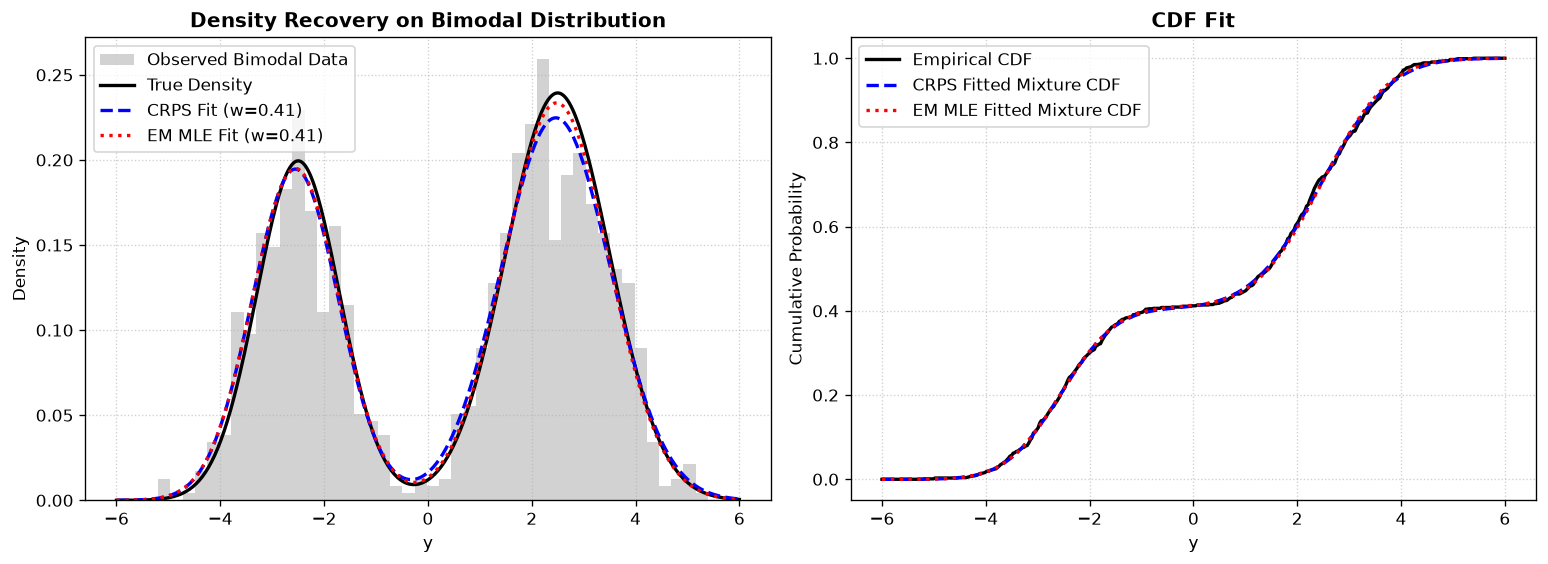

In [175]:
# No outliers
# -------------------------------------------------------------
# Optimize via CRPS vs Fit via EM (MLE)
# -------------------------------------------------------------
init_guess = [0.0, -1.0, np.log(1.5), 1.0, np.log(1.5)]  # [logit(0.5), -1, ln(1.5), 1, ln(1.5)]
res = minimize(objective_crps_gmm, init_guess, args=(y_obs,), method="L-BFGS-B")

w_crps = 1.0 / (1.0 + np.exp(-res.x[0]))
mu1_c, s1_c = res.x[1], np.exp(res.x[2])
mu2_c, s2_c = res.x[3], np.exp(res.x[4])

# Ensure mu1 < mu2 convention for printing
if mu1_c > mu2_c:
    w_crps, mu1_c, s1_c, mu2_c, s2_c = 1.0 - w_crps, mu2_c, s2_c, mu1_c, s1_c

# EM (MLE) Benchmark
gmm = GaussianMixture(n_components=2, random_state=42).fit(y_obs.reshape(-1, 1))
order = np.argsort(gmm.means_.flatten())
w_em = gmm.weights_[order[0]]
mu1_em, mu2_em = gmm.means_.flatten()[order]
s1_em, s2_em = np.sqrt(gmm.covariances_.flatten()[order])

print(f"{'Parameter':<10} | {'True':<8} | {'CRPS':<10} | {'EM (MLE)':<10}")
print("-" * 46)
print(f"{'w':<10} | {w_true:<8.3f} | {w_crps:<10.3f} | {w_em:<10.3f}")
print(f"{'mu_1':<10} | {mu1_true:<8.3f} | {mu1_c:<10.3f} | {mu1_em:<10.3f}")
print(f"{'sigma_1':<10} | {sigma1_true:<8.3f} | {s1_c:<10.3f} | {s1_em:<10.3f}")
print(f"{'mu_2':<10} | {mu2_true:<8.3f} | {mu2_c:<10.3f} | {mu2_em:<10.3f}")
print(f"{'sigma_2':<10} | {sigma2_true:<8.3f} | {s2_c:<10.3f} | {s2_em:<10.3f}")

# -------------------------------------------------------------
# Visualization: Mixture Density & CDF Fits
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)
x_grid = np.linspace(-6, 6, 400)

pdf_true = w_true * norm.pdf(x_grid, mu1_true, sigma1_true) + (1 - w_true) * norm.pdf(x_grid, mu2_true, sigma2_true)
pdf_crps = w_crps * norm.pdf(x_grid, mu1_c, s1_c) + (1 - w_crps) * norm.pdf(x_grid, mu2_c, s2_c)
pdf_em = w_em * norm.pdf(x_grid, mu1_em, s1_em) + (1 - w_em) * norm.pdf(x_grid, mu2_em, s2_em)

ax1.hist(y_obs, bins=45, density=True, color="gray", alpha=0.35, label="Observed Bimodal Data")
ax1.plot(x_grid, pdf_true, "k-", linewidth=2.0, label="True Density")
ax1.plot(x_grid, pdf_crps, "b--", linewidth=2.0, label=f"CRPS Fit (w={w_crps:.2f})")
ax1.plot(x_grid, pdf_em, "r:", linewidth=2.0, label=f"EM MLE Fit (w={w_em:.2f})")
ax1.set_title("Density Recovery on Bimodal Distribution", fontweight="bold")
ax1.set_xlabel("y")
ax1.set_ylabel("Density")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)

# CDF Comparison
cdf_emp = np.array([np.mean(y_obs <= x) for x in x_grid])
cdf_crps = w_crps * norm.cdf(x_grid, mu1_c, s1_c) + (1 - w_crps) * norm.cdf(x_grid, mu2_c, s2_c)
cdf_em = w_em * norm.cdf(x_grid, mu1_em, s1_em) + (1 - w_em) * norm.cdf(x_grid, mu2_em, s2_em)

ax2.plot(x_grid, cdf_emp, "k-", linewidth=2.0, label="Empirical CDF")
ax2.plot(x_grid, cdf_crps, "b--", linewidth=2.0, label="CRPS Fitted Mixture CDF")
ax2.plot(x_grid, cdf_em, "r:", linewidth=2.0, label="EM MLE Fitted Mixture CDF")
ax2.set_title("CDF Fit", fontweight="bold")
ax2.set_xlabel("y")
ax2.set_ylabel("Cumulative Probability")
ax2.legend()
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

In [176]:
n_trials = 1000     # Number of repetitions
n_samples = 1000    # Sample size per trial
w_true = 0.4
mu1_true, sigma1_true = -2.5, 0.8
mu2_true, sigma2_true = 2.5, 1.0

# Storage for results
mu_1_crps_list = []
sigma_1_crps_list = []
mu_2_crps_list = []
sigma_2_crps_list = []
w_crps_list = []
mu_1_mle_list = []
sigma_1_mle_list = []
mu_2_mle_list = []
sigma_2_mle_list = []
w_mle_list = []

for trial in range(n_trials):
    # Generate fresh synthetic data
    comp = np.random.binomial(1, 1 - w_true, size=n_samples)
    y_obs = np.where(
        comp == 0,
        np.random.normal(mu1_true, sigma1_true, size=n_samples),
        np.random.normal(mu2_true, sigma2_true, size=n_samples)
    )
    
    # Maximum Likelihood Estimation
    gmm = GaussianMixture(n_components=2, random_state=42).fit(y_obs.reshape(-1, 1))
    order = np.argsort(gmm.means_.flatten())
    w_em = gmm.weights_[order[0]]
    mu1_em, mu2_em = gmm.means_.flatten()[order]
    s1_em, s2_em = np.sqrt(gmm.covariances_.flatten()[order])

    mu_1_mle_list.append(mu1_em)
    sigma_1_mle_list.append(s1_em)
    mu_2_mle_list.append(mu2_em)
    sigma_2_mle_list.append(s2_em)
    w_mle_list.append(w_em)

    # Minimum CRPS Estimation (numerical optimization)
    init_guess = [0.0, -1.0, np.log(1.5), 1.0, np.log(1.5)]  # [logit(0.5), -1, ln(1.5), 1, ln(1.5)]
    res = minimize(objective_crps_gmm, init_guess, args=(y_obs,), method="L-BFGS-B")

    w_crps = 1.0 / (1.0 + np.exp(-res.x[0]))
    mu1_c, s1_c = res.x[1], np.exp(res.x[2])
    mu2_c, s2_c = res.x[3], np.exp(res.x[4])
    
    mu_1_crps_list.append(mu1_c)
    sigma_1_crps_list.append(s1_c)
    mu_2_crps_list.append(mu2_c)
    sigma_2_crps_list.append(s2_c)  
    w_crps_list.append(w_crps)

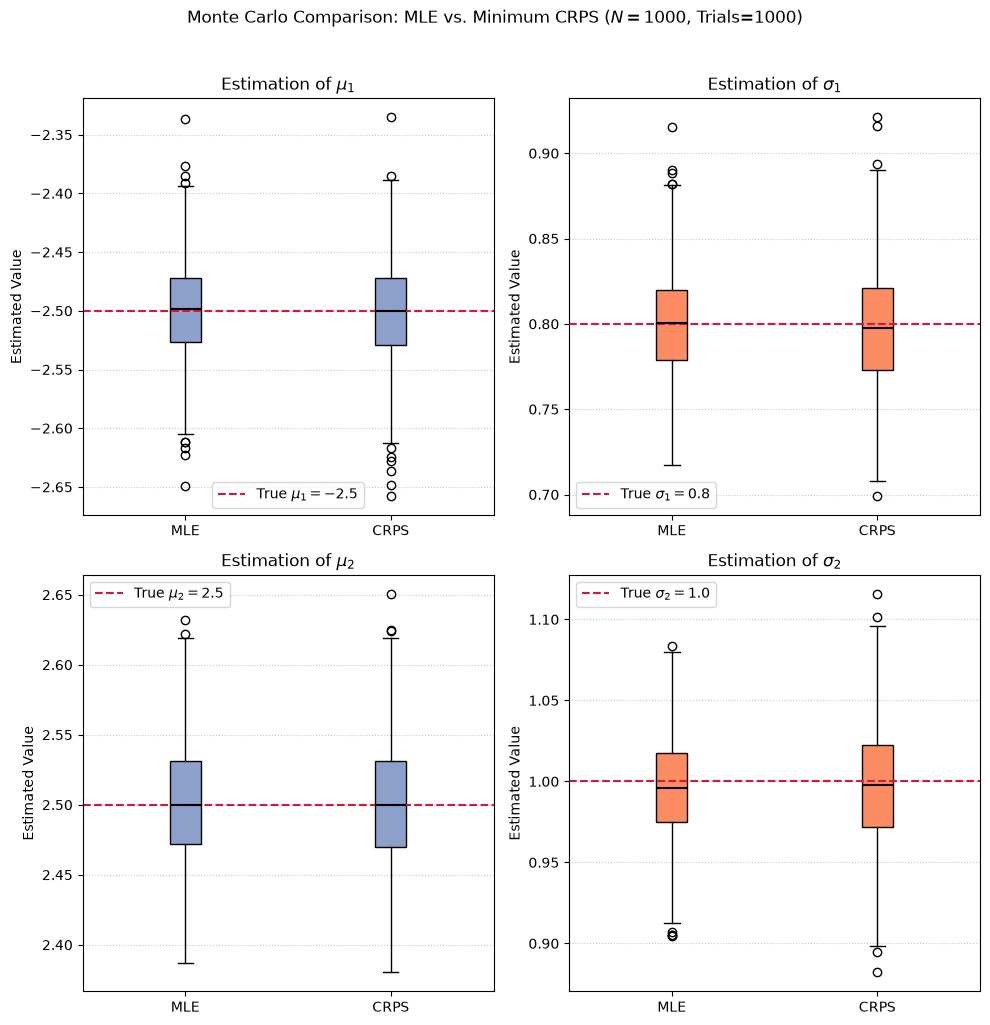

In [177]:
# Visualization: Side-by-Side Box Plots
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Plot for mu estimation
data_mu_1 = [mu_1_mle_list, mu_1_crps_list]
axes[0, 0].boxplot(data_mu_1, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes[0, 0].axhline(mu1_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu_1 = {mu1_true}$')
axes[0, 0].set_title(r'Estimation of $\mu_1$')
axes[0, 0].set_ylabel('Estimated Value')
axes[0, 0].grid(axis='y', linestyle=':', alpha=0.7)
axes[0, 0].legend()

# Plot for sigma estimation
data_sigma_1 = [sigma_1_mle_list, sigma_1_crps_list]
axes[0, 1].boxplot(data_sigma_1, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[0, 1].axhline(sigma1_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma_1 = {sigma1_true}$')
axes[0, 1].set_title(r'Estimation of $\sigma_1$')
axes[0, 1].set_ylabel('Estimated Value')
axes[0, 1].grid(axis='y', linestyle=':', alpha=0.7)
axes[0, 1].legend()

# Plot for mu estimation
data_mu_2 = [mu_2_mle_list, mu_2_crps_list]
axes[1, 0].boxplot(data_mu_2, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                    medianprops=dict(color='black', linewidth=1.5))
axes[1, 0].axhline(mu2_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu_2 = {mu2_true}$')
axes[1, 0].set_title(r'Estimation of $\mu_2$')
axes[1, 0].set_ylabel('Estimated Value')
axes[1, 0].grid(axis='y', linestyle=':', alpha=0.7)
axes[1, 0].legend()

# Plot for sigma estimation
data_sigma_2 = [sigma_2_mle_list, sigma_2_crps_list]
axes[1, 1].boxplot(data_sigma_2, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[1, 1].axhline(sigma2_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma_2 = {sigma2_true}$')
axes[1, 1].set_title(r'Estimation of $\sigma_2$')
axes[1, 1].set_ylabel('Estimated Value')
axes[1, 1].grid(axis='y', linestyle=':', alpha=0.7)
axes[1, 1].legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.show()

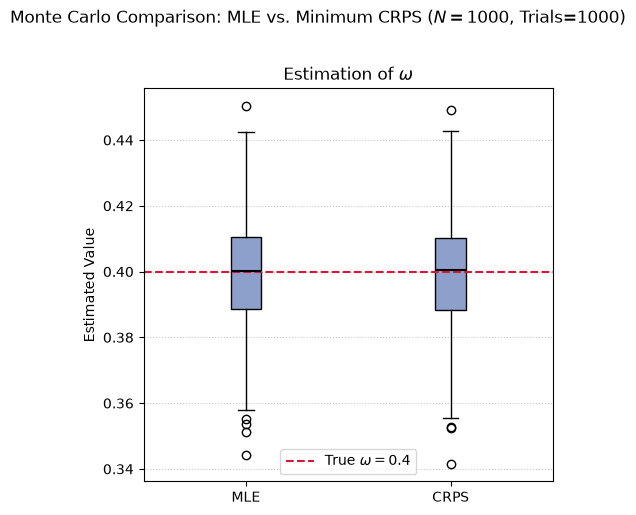

In [178]:
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
data_w = [w_mle_list, w_crps_list]
axes.boxplot(data_w, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes.axhline(w_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\omega = {w_true}$')
axes.set_title(r'Estimation of $\omega$')
axes.set_ylabel('Estimated Value')
axes.grid(axis='y', linestyle=':', alpha=0.7)
axes.legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.show()

Original shape: (1000,) | Noisy shape: (1000,)
Parameter  | True     | CRPS       | EM (MLE)  
----------------------------------------------
w          | 0.400    | 0.396      | 0.398     
mu_1       | -2.500   | -2.527     | -2.570    
sigma_1    | 0.800    | 0.814      | 1.006     
mu_2       | 2.500    | 2.536      | 2.583     
sigma_2    | 1.000    | 1.066      | 1.145     


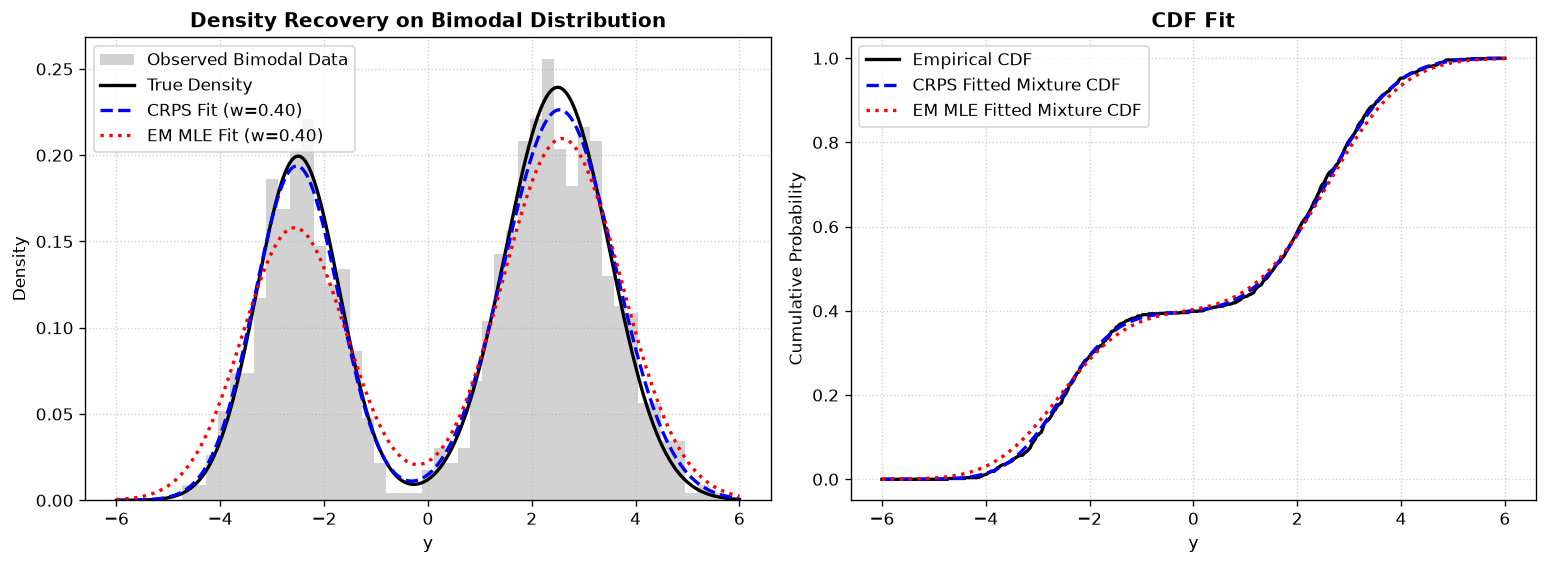

In [179]:
# 2% outliers
outlier_rate = 0.02 
n_outliers = int(outlier_rate * n_samples)

# Uniform[-12, 12]
outliers = np.random.uniform(low=-12, high=12, size=n_outliers)

# Randomly select which indices to replace with noise
outlier_indices = np.random.choice(n_samples, size=n_outliers, replace=False)
y_noisy = y_obs.copy()
y_noisy[outlier_indices] = outliers

print(f"Original shape: {y_obs.shape} | Noisy shape: {y_noisy.shape}")

# -------------------------------------------------------------
# Optimize via CRPS vs Fit via EM (MLE)
# -------------------------------------------------------------
init_guess = [0.0, -1.0, np.log(1.5), 1.0, np.log(1.5)]  # [logit(0.5), -1, ln(1.5), 1, ln(1.5)]
res = minimize(objective_crps_gmm, init_guess, args=(y_noisy,), method="L-BFGS-B")

w_crps = 1.0 / (1.0 + np.exp(-res.x[0]))
mu1_c, s1_c = res.x[1], np.exp(res.x[2])
mu2_c, s2_c = res.x[3], np.exp(res.x[4])

# Ensure mu1 < mu2 convention for printing
if mu1_c > mu2_c:
    w_crps, mu1_c, s1_c, mu2_c, s2_c = 1.0 - w_crps, mu2_c, s2_c, mu1_c, s1_c

# EM (MLE) Benchmark
gmm = GaussianMixture(n_components=2, random_state=42).fit(y_noisy.reshape(-1, 1))
order = np.argsort(gmm.means_.flatten())
w_em = gmm.weights_[order[0]]
mu1_em, mu2_em = gmm.means_.flatten()[order]
s1_em, s2_em = np.sqrt(gmm.covariances_.flatten()[order])

print(f"{'Parameter':<10} | {'True':<8} | {'CRPS':<10} | {'EM (MLE)':<10}")
print("-" * 46)
print(f"{'w':<10} | {w_true:<8.3f} | {w_crps:<10.3f} | {w_em:<10.3f}")
print(f"{'mu_1':<10} | {mu1_true:<8.3f} | {mu1_c:<10.3f} | {mu1_em:<10.3f}")
print(f"{'sigma_1':<10} | {sigma1_true:<8.3f} | {s1_c:<10.3f} | {s1_em:<10.3f}")
print(f"{'mu_2':<10} | {mu2_true:<8.3f} | {mu2_c:<10.3f} | {mu2_em:<10.3f}")
print(f"{'sigma_2':<10} | {sigma2_true:<8.3f} | {s2_c:<10.3f} | {s2_em:<10.3f}")

# -------------------------------------------------------------
# Visualization: Mixture Density & CDF Fits
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)
x_grid = np.linspace(-6, 6, 400)

pdf_true = w_true * norm.pdf(x_grid, mu1_true, sigma1_true) + (1 - w_true) * norm.pdf(x_grid, mu2_true, sigma2_true)
pdf_crps = w_crps * norm.pdf(x_grid, mu1_c, s1_c) + (1 - w_crps) * norm.pdf(x_grid, mu2_c, s2_c)
pdf_em = w_em * norm.pdf(x_grid, mu1_em, s1_em) + (1 - w_em) * norm.pdf(x_grid, mu2_em, s2_em)

ax1.hist(y_obs, bins=45, density=True, color="gray", alpha=0.35, label="Observed Bimodal Data")
ax1.plot(x_grid, pdf_true, "k-", linewidth=2.0, label="True Density")
ax1.plot(x_grid, pdf_crps, "b--", linewidth=2.0, label=f"CRPS Fit (w={w_crps:.2f})")
ax1.plot(x_grid, pdf_em, "r:", linewidth=2.0, label=f"EM MLE Fit (w={w_em:.2f})")
ax1.set_title("Density Recovery on Bimodal Distribution", fontweight="bold")
ax1.set_xlabel("y")
ax1.set_ylabel("Density")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)

# CDF Comparison
cdf_emp = np.array([np.mean(y_obs <= x) for x in x_grid])
cdf_crps = w_crps * norm.cdf(x_grid, mu1_c, s1_c) + (1 - w_crps) * norm.cdf(x_grid, mu2_c, s2_c)
cdf_em = w_em * norm.cdf(x_grid, mu1_em, s1_em) + (1 - w_em) * norm.cdf(x_grid, mu2_em, s2_em)

ax2.plot(x_grid, cdf_emp, "k-", linewidth=2.0, label="Empirical CDF")
ax2.plot(x_grid, cdf_crps, "b--", linewidth=2.0, label="CRPS Fitted Mixture CDF")
ax2.plot(x_grid, cdf_em, "r:", linewidth=2.0, label="EM MLE Fitted Mixture CDF")
ax2.set_title("CDF Fit", fontweight="bold")
ax2.set_xlabel("y")
ax2.set_ylabel("Cumulative Probability")
ax2.legend()
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

In [180]:
# 2% outliers - 1000 trials
n_trials = 1000     # Number of repetitions
n_samples = 1000    # Sample size per trial
outlier_rate = 0.02 
n_outliers = int(outlier_rate * n_samples)
w_true = 0.4
mu1_true, sigma1_true = -2.5, 0.8
mu2_true, sigma2_true = 2.5, 1.0

# Storage for results
mu_1_crps_list = []
sigma_1_crps_list = []
mu_2_crps_list = []
sigma_2_crps_list = []
w_crps_list = []
mu_1_mle_list = []
sigma_1_mle_list = []
mu_2_mle_list = []
sigma_2_mle_list = []
w_mle_list = []

for trial in range(n_trials):
    # Generate fresh synthetic data
    comp = np.random.binomial(1, 1 - w_true, size=n_samples)
    y_obs = np.where(
        comp == 0,
        np.random.normal(mu1_true, sigma1_true, size=n_samples),
        np.random.normal(mu2_true, sigma2_true, size=n_samples)
    )
    # Uniform[-12, 12]
    outliers = np.random.uniform(low=-12, high=12, size=n_outliers)

    # Randomly select which indices to replace with noise
    outlier_indices = np.random.choice(n_samples, size=n_outliers, replace=False)
    y_noisy = y_obs.copy()
    y_noisy[outlier_indices] = outliers
    
    # Maximum Likelihood Estimation
    gmm = GaussianMixture(n_components=2, random_state=42).fit(y_noisy.reshape(-1, 1))
    order = np.argsort(gmm.means_.flatten())
    w_em = gmm.weights_[order[0]]
    mu1_em, mu2_em = gmm.means_.flatten()[order]
    s1_em, s2_em = np.sqrt(gmm.covariances_.flatten()[order])

    mu_1_mle_list.append(mu1_em)
    sigma_1_mle_list.append(s1_em)
    mu_2_mle_list.append(mu2_em)
    sigma_2_mle_list.append(s2_em)
    w_mle_list.append(w_em)

    # Minimum CRPS Estimation (numerical optimization)
    init_guess = [0.0, -1.0, np.log(1.5), 1.0, np.log(1.5)]  # [logit(0.5), -1, ln(1.5), 1, ln(1.5)]
    res = minimize(objective_crps_gmm, init_guess, args=(y_noisy,), method="L-BFGS-B")

    w_crps = 1.0 / (1.0 + np.exp(-res.x[0]))
    mu1_c, s1_c = res.x[1], np.exp(res.x[2])
    mu2_c, s2_c = res.x[3], np.exp(res.x[4])
    
    mu_1_crps_list.append(mu1_c)
    sigma_1_crps_list.append(s1_c)
    mu_2_crps_list.append(mu2_c)
    sigma_2_crps_list.append(s2_c)  
    w_crps_list.append(w_crps)

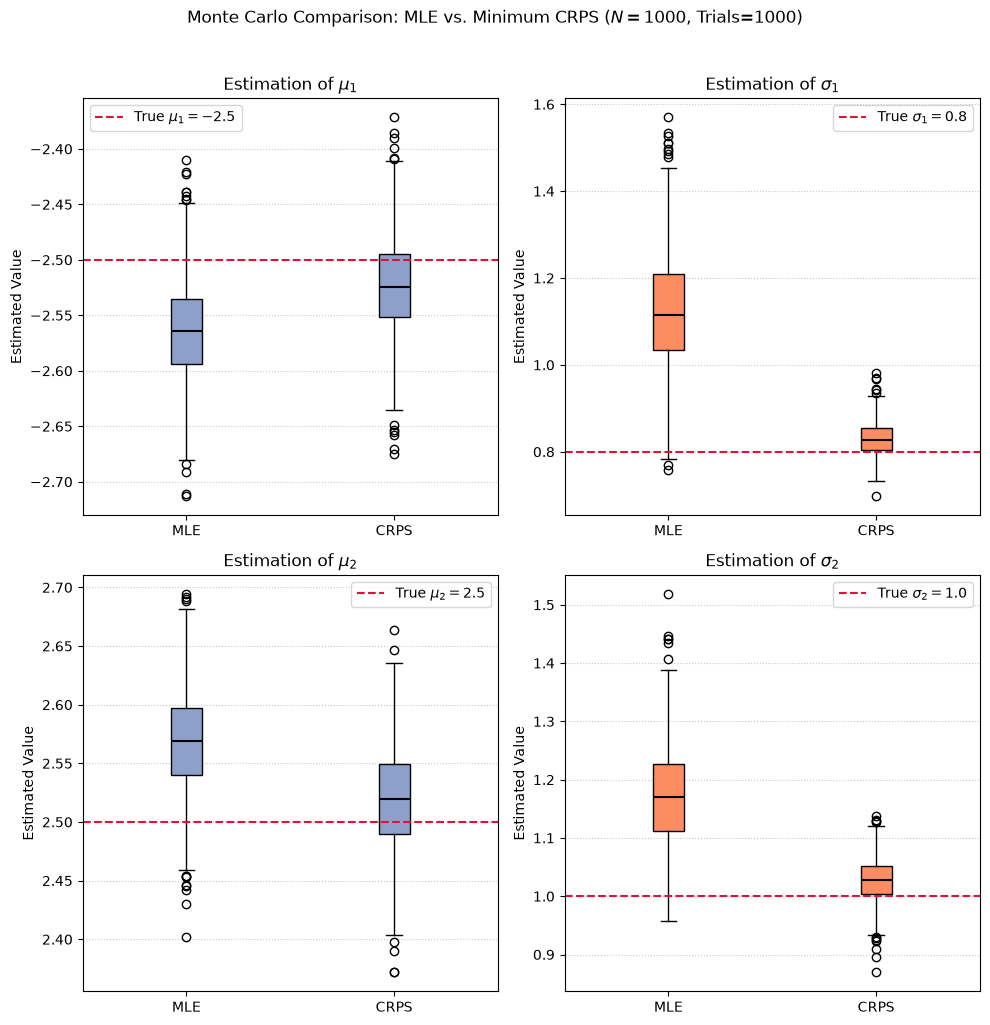

In [181]:
# Visualization: Side-by-Side Box Plots
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Plot for mu estimation
data_mu_1 = [mu_1_mle_list, mu_1_crps_list]
axes[0, 0].boxplot(data_mu_1, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes[0, 0].axhline(mu1_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu_1 = {mu1_true}$')
axes[0, 0].set_title(r'Estimation of $\mu_1$')
axes[0, 0].set_ylabel('Estimated Value')
axes[0, 0].grid(axis='y', linestyle=':', alpha=0.7)
axes[0, 0].legend()

# Plot for sigma estimation
data_sigma_1 = [sigma_1_mle_list, sigma_1_crps_list]
axes[0, 1].boxplot(data_sigma_1, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[0, 1].axhline(sigma1_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma_1 = {sigma1_true}$')
axes[0, 1].set_title(r'Estimation of $\sigma_1$')
axes[0, 1].set_ylabel('Estimated Value')
axes[0, 1].grid(axis='y', linestyle=':', alpha=0.7)
axes[0, 1].legend()

# Plot for mu estimation
data_mu_2 = [mu_2_mle_list, mu_2_crps_list]
axes[1, 0].boxplot(data_mu_2, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                    medianprops=dict(color='black', linewidth=1.5))
axes[1, 0].axhline(mu2_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu_2 = {mu2_true}$')
axes[1, 0].set_title(r'Estimation of $\mu_2$')
axes[1, 0].set_ylabel('Estimated Value')
axes[1, 0].grid(axis='y', linestyle=':', alpha=0.7)
axes[1, 0].legend()

# Plot for sigma estimation
data_sigma_2 = [sigma_2_mle_list, sigma_2_crps_list]
axes[1, 1].boxplot(data_sigma_2, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[1, 1].axhline(sigma2_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma_2 = {sigma2_true}$')
axes[1, 1].set_title(r'Estimation of $\sigma_2$')
axes[1, 1].set_ylabel('Estimated Value')
axes[1, 1].grid(axis='y', linestyle=':', alpha=0.7)
axes[1, 1].legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.show()

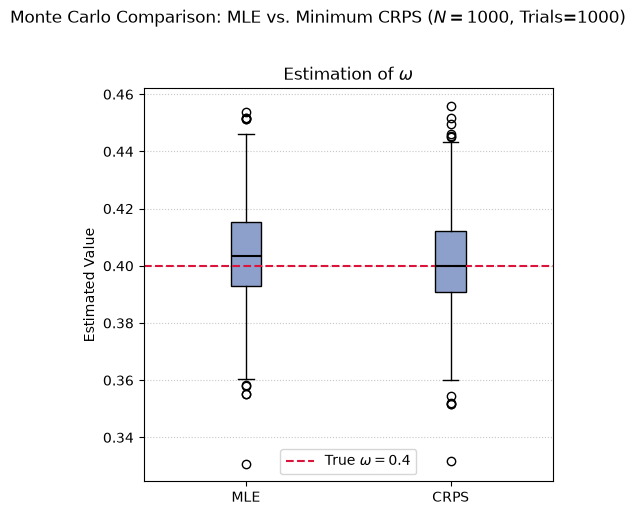

In [182]:
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
data_w = [w_mle_list, w_crps_list]
axes.boxplot(data_w, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes.axhline(w_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\omega = {w_true}$')
axes.set_title(r'Estimation of $\omega$')
axes.set_ylabel('Estimated Value')
axes.grid(axis='y', linestyle=':', alpha=0.7)
axes.legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.show()

Original shape: (1000,) | Noisy shape: (1000,)
Parameter  | True     | CRPS       | EM (MLE)  
----------------------------------------------
w          | 0.400    | 0.409      | 0.449     
mu_1       | -2.500   | -2.618     | -2.531    
sigma_1    | 0.800    | 0.965      | 2.491     
mu_2       | 2.500    | 2.671      | 2.850     
sigma_2    | 1.000    | 1.188      | 1.759     


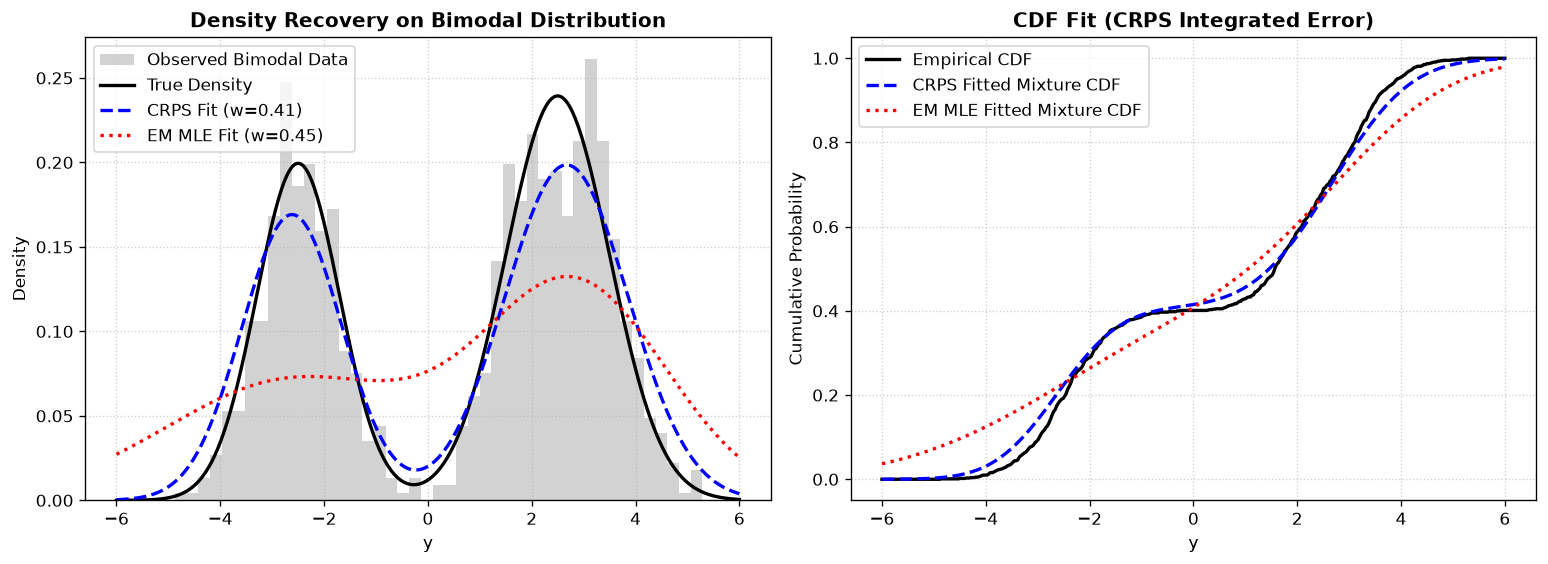

In [183]:
# 10% noise 
outlier_rate = 0.10  
n_outliers = int(outlier_rate * n_samples)

# Uniform[-12, 12]
outliers = np.random.uniform(low=-12, high=12, size=n_outliers)

# Randomly select which indices to replace with noise
outlier_indices = np.random.choice(n_samples, size=n_outliers, replace=False)
y_noisy = y_obs.copy()
y_noisy[outlier_indices] = outliers

print(f"Original shape: {y_obs.shape} | Noisy shape: {y_noisy.shape}")

# -------------------------------------------------------------
# Optimize via CRPS vs Fit via EM (MLE)
# -------------------------------------------------------------
init_guess = [0.0, -1.0, np.log(1.5), 1.0, np.log(1.5)]  # [logit(0.5), -1, ln(1.5), 1, ln(1.5)]
res = minimize(objective_crps_gmm, init_guess, args=(y_noisy,), method="L-BFGS-B")

w_crps = 1.0 / (1.0 + np.exp(-res.x[0]))
mu1_c, s1_c = res.x[1], np.exp(res.x[2])
mu2_c, s2_c = res.x[3], np.exp(res.x[4])

# Ensure mu1 < mu2 convention for printing
if mu1_c > mu2_c:
    w_crps, mu1_c, s1_c, mu2_c, s2_c = 1.0 - w_crps, mu2_c, s2_c, mu1_c, s1_c

# EM (MLE) Benchmark
gmm = GaussianMixture(n_components=2, random_state=42).fit(y_noisy.reshape(-1, 1))
order = np.argsort(gmm.means_.flatten())
w_em = gmm.weights_[order[0]]
mu1_em, mu2_em = gmm.means_.flatten()[order]
s1_em, s2_em = np.sqrt(gmm.covariances_.flatten()[order])

print(f"{'Parameter':<10} | {'True':<8} | {'CRPS':<10} | {'EM (MLE)':<10}")
print("-" * 46)
print(f"{'w':<10} | {w_true:<8.3f} | {w_crps:<10.3f} | {w_em:<10.3f}")
print(f"{'mu_1':<10} | {mu1_true:<8.3f} | {mu1_c:<10.3f} | {mu1_em:<10.3f}")
print(f"{'sigma_1':<10} | {sigma1_true:<8.3f} | {s1_c:<10.3f} | {s1_em:<10.3f}")
print(f"{'mu_2':<10} | {mu2_true:<8.3f} | {mu2_c:<10.3f} | {mu2_em:<10.3f}")
print(f"{'sigma_2':<10} | {sigma2_true:<8.3f} | {s2_c:<10.3f} | {s2_em:<10.3f}")

# -------------------------------------------------------------
# Visualization: Mixture Density & CDF Fits
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)
x_grid = np.linspace(-6, 6, 400)

pdf_true = w_true * norm.pdf(x_grid, mu1_true, sigma1_true) + (1 - w_true) * norm.pdf(x_grid, mu2_true, sigma2_true)
pdf_crps = w_crps * norm.pdf(x_grid, mu1_c, s1_c) + (1 - w_crps) * norm.pdf(x_grid, mu2_c, s2_c)
pdf_em = w_em * norm.pdf(x_grid, mu1_em, s1_em) + (1 - w_em) * norm.pdf(x_grid, mu2_em, s2_em)

ax1.hist(y_obs, bins=45, density=True, color="gray", alpha=0.35, label="Observed Bimodal Data")
ax1.plot(x_grid, pdf_true, "k-", linewidth=2.0, label="True Density")
ax1.plot(x_grid, pdf_crps, "b--", linewidth=2.0, label=f"CRPS Fit (w={w_crps:.2f})")
ax1.plot(x_grid, pdf_em, "r:", linewidth=2.0, label=f"EM MLE Fit (w={w_em:.2f})")
ax1.set_title("Density Recovery on Bimodal Distribution", fontweight="bold")
ax1.set_xlabel("y")
ax1.set_ylabel("Density")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)

# CDF Comparison
cdf_emp = np.array([np.mean(y_obs <= x) for x in x_grid])
cdf_crps = w_crps * norm.cdf(x_grid, mu1_c, s1_c) + (1 - w_crps) * norm.cdf(x_grid, mu2_c, s2_c)
cdf_em = w_em * norm.cdf(x_grid, mu1_em, s1_em) + (1 - w_em) * norm.cdf(x_grid, mu2_em, s2_em)

ax2.plot(x_grid, cdf_emp, "k-", linewidth=2.0, label="Empirical CDF")
ax2.plot(x_grid, cdf_crps, "b--", linewidth=2.0, label="CRPS Fitted Mixture CDF")
ax2.plot(x_grid, cdf_em, "r:", linewidth=2.0, label="EM MLE Fitted Mixture CDF")
ax2.set_title("CDF Fit (CRPS Integrated Error)", fontweight="bold")
ax2.set_xlabel("y")
ax2.set_ylabel("Cumulative Probability")
ax2.legend()
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

In [184]:
# 10% outliers - 1000 trials
n_trials = 1000     # Number of repetitions
n_samples = 1000    # Sample size per trial
outlier_rate = 0.10 
n_outliers = int(outlier_rate * n_samples)
w_true = 0.4
mu1_true, sigma1_true = -2.5, 0.8
mu2_true, sigma2_true = 2.5, 1.0

# Storage for results
mu_1_crps_list = []
sigma_1_crps_list = []
mu_2_crps_list = []
sigma_2_crps_list = []
w_crps_list = []
mu_1_mle_list = []
sigma_1_mle_list = []
mu_2_mle_list = []
sigma_2_mle_list = []
w_mle_list = []

for trial in range(n_trials):
    # Generate fresh synthetic data
    comp = np.random.binomial(1, 1 - w_true, size=n_samples)
    y_obs = np.where(
        comp == 0,
        np.random.normal(mu1_true, sigma1_true, size=n_samples),
        np.random.normal(mu2_true, sigma2_true, size=n_samples)
    )
    # Uniform[-12, 12]
    outliers = np.random.uniform(low=-12, high=12, size=n_outliers)

    # Randomly select which indices to replace with noise
    outlier_indices = np.random.choice(n_samples, size=n_outliers, replace=False)
    y_noisy = y_obs.copy()
    y_noisy[outlier_indices] = outliers
    
    # Maximum Likelihood Estimation
    gmm = GaussianMixture(n_components=2, random_state=42).fit(y_noisy.reshape(-1, 1))
    order = np.argsort(gmm.means_.flatten())
    w_em = gmm.weights_[order[0]]
    mu1_em, mu2_em = gmm.means_.flatten()[order]
    s1_em, s2_em = np.sqrt(gmm.covariances_.flatten()[order])

    mu_1_mle_list.append(mu1_em)
    sigma_1_mle_list.append(s1_em)
    mu_2_mle_list.append(mu2_em)
    sigma_2_mle_list.append(s2_em)
    w_mle_list.append(w_em)

    # Minimum CRPS Estimation (numerical optimization)
    init_guess = [0.0, -1.0, np.log(1.5), 1.0, np.log(1.5)]  # [logit(0.5), -1, ln(1.5), 1, ln(1.5)]
    res = minimize(objective_crps_gmm, init_guess, args=(y_noisy,), method="L-BFGS-B")

    w_crps = 1.0 / (1.0 + np.exp(-res.x[0]))
    mu1_c, s1_c = res.x[1], np.exp(res.x[2])
    mu2_c, s2_c = res.x[3], np.exp(res.x[4])
    
    mu_1_crps_list.append(mu1_c)
    sigma_1_crps_list.append(s1_c)
    mu_2_crps_list.append(mu2_c)
    sigma_2_crps_list.append(s2_c)  
    w_crps_list.append(w_crps)

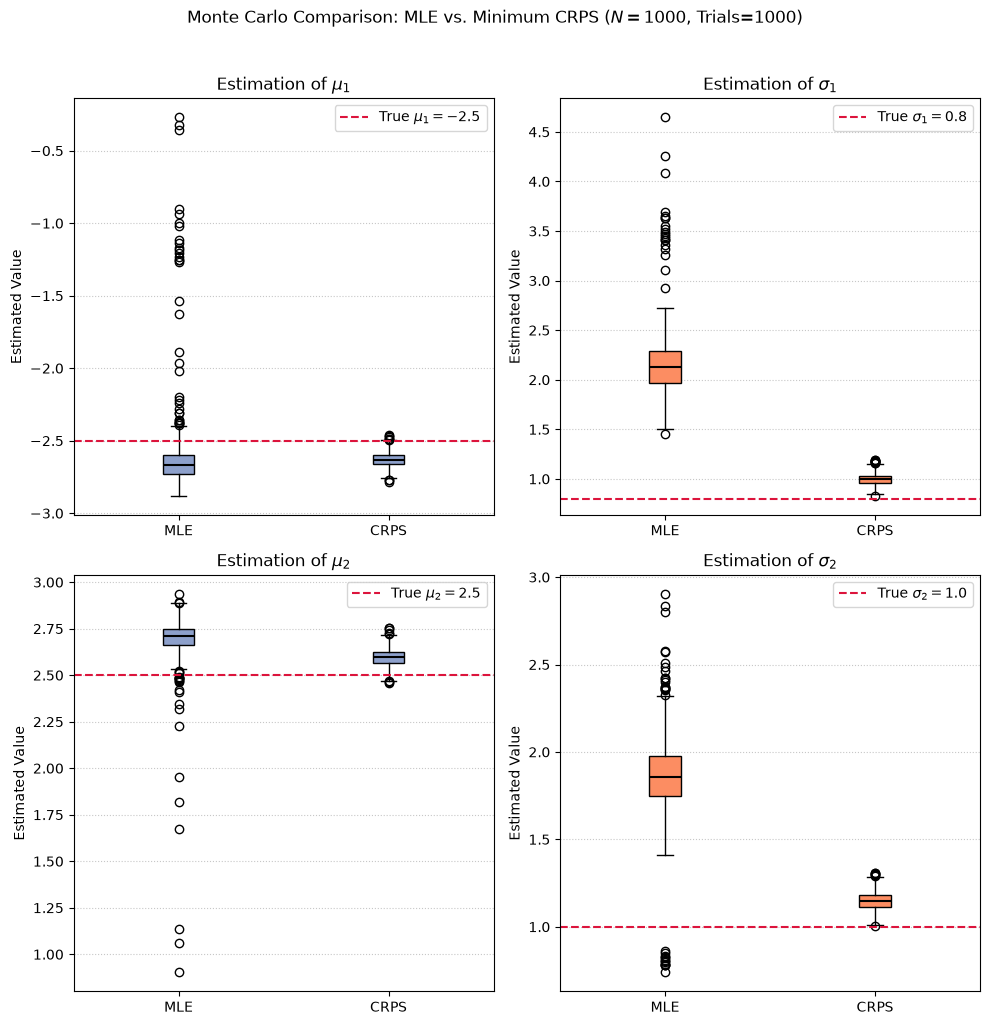

In [185]:
# Visualization: Side-by-Side Box Plots
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Plot for mu estimation
data_mu_1 = [mu_1_mle_list, mu_1_crps_list]
axes[0, 0].boxplot(data_mu_1, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes[0, 0].axhline(mu1_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu_1 = {mu1_true}$')
axes[0, 0].set_title(r'Estimation of $\mu_1$')
axes[0, 0].set_ylabel('Estimated Value')
axes[0, 0].grid(axis='y', linestyle=':', alpha=0.7)
axes[0, 0].legend()

# Plot for sigma estimation
data_sigma_1 = [sigma_1_mle_list, sigma_1_crps_list]
axes[0, 1].boxplot(data_sigma_1, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[0, 1].axhline(sigma1_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma_1 = {sigma1_true}$')
axes[0, 1].set_title(r'Estimation of $\sigma_1$')
axes[0, 1].set_ylabel('Estimated Value')
axes[0, 1].grid(axis='y', linestyle=':', alpha=0.7)
axes[0, 1].legend()

# Plot for mu estimation
data_mu_2 = [mu_2_mle_list, mu_2_crps_list]
axes[1, 0].boxplot(data_mu_2, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                    medianprops=dict(color='black', linewidth=1.5))
axes[1, 0].axhline(mu2_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\mu_2 = {mu2_true}$')
axes[1, 0].set_title(r'Estimation of $\mu_2$')
axes[1, 0].set_ylabel('Estimated Value')
axes[1, 0].grid(axis='y', linestyle=':', alpha=0.7)
axes[1, 0].legend()

# Plot for sigma estimation
data_sigma_2 = [sigma_2_mle_list, sigma_2_crps_list]
axes[1, 1].boxplot(data_sigma_2, tick_labels=['MLE', 'CRPS'], patch_artist=True,
                   boxprops=dict(facecolor='#fc8d62', color='black'),
                   medianprops=dict(color='black', linewidth=1.5))
axes[1, 1].axhline(sigma2_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\sigma_2 = {sigma2_true}$')
axes[1, 1].set_title(r'Estimation of $\sigma_2$')
axes[1, 1].set_ylabel('Estimated Value')
axes[1, 1].grid(axis='y', linestyle=':', alpha=0.7)
axes[1, 1].legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.show()

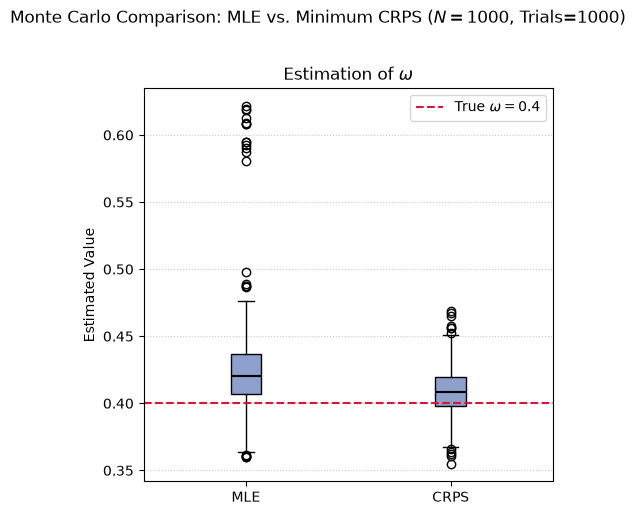

In [186]:
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
data_w = [w_mle_list, w_crps_list]
axes.boxplot(data_w, tick_labels=['MLE', 'CRPS'], patch_artist=True, 
                    boxprops=dict(facecolor='#8da0cb', color='black'), 
                medianprops=dict(color='black', linewidth=1.5))
axes.axhline(w_true, color='crimson', linestyle='--', linewidth=1.5, label=f'True $\\omega = {w_true}$')
axes.set_title(r'Estimation of $\omega$')
axes.set_ylabel('Estimated Value')
axes.grid(axis='y', linestyle=':', alpha=0.7)
axes.legend()

plt.suptitle(f'Monte Carlo Comparison: MLE vs. Minimum CRPS ($N={n_samples}$, Trials={n_trials})', y=1.02)
plt.tight_layout()
plt.show()